# Avaliação Modelo 1

In [2]:
import re
import string
import unicodedata
import pandas as pd
import spacy as scy
import os
from joblib import load
from itertools import product
from unidecode import unidecode
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer

In [3]:
import os
from dotenv import load_dotenv
from pathlib import Path

# Como o notebook está em 'corretor/src/3_avaliacao' e o .env em 'corretor',
# precisamos voltar duas pastas (../..) para achar o arquivo.
env_path = Path('../../.env')

# Carrega o arquivo explicitamente
load_dotenv(dotenv_path=env_path)

True

In [4]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\joaol\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

### Como o modelo antigo se comporta com os mesmos dados?

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [6]:
rf_e2 = load('../../rf_exp2.joblib')

In [7]:
PATH_BASE_TESTES_FINAIS = os.getenv('PATH_BASE_TESTES_FINAIS')
PATH_GABARITO_CORRETOR = os.getenv('PATH_GABARITO_CORRETOR')
PATH_FALSOS_NEGATIVOS_MODELO_1 = os.getenv('PATH_FALSOS_NEGATIVOS_MODELO_1')

In [8]:
base_relato = pd.read_csv(PATH_BASE_TESTES_FINAIS)

## Criando saída do modelo

In [9]:
######################################################################################################################################################
# Pré-Processamento dos relatos
######################################################################################################################################################
def preprocess(relato):
    def remove_stop_words(relato):
        # Remove stop words em português
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        # Remoção de números e pontuação
        relato = re.sub(r'\@(\w*\d?)', " ", relato)
        relato = re.sub(r'([A-z1-9]*_+[A-z1-9]*)|(_+[A-z1-9]*)|([A-z1-9]*_+)', " ", relato)
        relato = re.sub(r"((?:HTTPS?|WWW)(?:\:\/\/?)?[*a-zA-Z0-9\.\/\?\:@\-_=#]+[\.][a-zA-Z]{2,6}[a-zA-Z0-9\.\&\/\?\:@\-_=#]*)", " ", relato)
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

print("Iniciando pré-processamento...")
base_relato['relato'] = base_relato['relato'].apply(normalize_text)
base_relato['relato_tratado'] = base_relato['relato'].apply(preprocess)
print("Pré-processamento finalizado!")
######################################################################################################################################################
# Predição utilizando o modelo1
######################################################################################################################################################
def loadOutputList(df_bop : pd.DataFrame):
    rf_exp_2 = load('../../rf_exp2.joblib')

    output_list = []

    for text in df_bop['relato_tratado']:
        text = text.split()
        df = pd.DataFrame(text, columns=['pred_palavra'])

        df['y_palavra'] = rf_exp_2.predict(df['pred_palavra'].to_list())

        for _, row in df.iterrows():
            output_list.append({
                'pred_palavra': row['pred_palavra'],
                'y_palavra': int(row['y_palavra']),
            })
        output_list.append({
                'pred_palavra': '#',
                'y_palavra': 2,
            })
    
    output_list.pop()

    return pd.DataFrame(output_list)
print("Carregando predição do modelo...")
output_list = loadOutputList(base_relato)
print("Base de dados de predição criada!")
######################################################################################################################################################

Iniciando pré-processamento...
Pré-processamento finalizado!
Carregando predição do modelo...
Base de dados de predição criada!


In [10]:
gab = pd.read_csv(PATH_GABARITO_CORRETOR)

In [11]:
gab

,palavra,y
0,MARIETA,1
1,LUZ,1
2,ELIANE,1
3,GUSMÃO,1
4,MAURICIO,1
...,...,...
11620,ICARAI,0
11621,PROCEDIMENTO,0
11622,AMARO,0
11623,PONTUACAO,0


mapeamento das palavras contidas na lista de saida ( output_list ) que estão contidas na coluna 'palavra' do gabarito

In [12]:
test_output_list = output_list.copy()

In [13]:
test_output_list

,pred_palavra,y_palavra
0,SUBJETIVO,0
1,NEFROLOGIA,1
2,ALICE,1
3,MORAES,1
4,ANOS,0
...,...,...
233678,BAIRRO,1
233679,BANCARIOS,0
233680,MORADOR,0
233681,RIO,1


In [14]:
teste2 = test_output_list.merge(gab[['palavra', 'y']], left_on='pred_palavra', right_on='palavra', how='left')

teste2['y'] = teste2['y'].fillna(0).astype(int)

teste2 = teste2[teste2['y_palavra'] != 2]
teste2

,pred_palavra,y_palavra,palavra,y
0,SUBJETIVO,0,SUBJETIVO,0
1,NEFROLOGIA,1,NEFROLOGIA,0
2,ALICE,1,ALICE,1
3,MORAES,1,MORAES,1
4,ANOS,0,ANOS,0
...,...,...,...,...
233678,BAIRRO,1,BAIRRO,0
233679,BANCARIOS,0,BANCARIOS,0
233680,MORADOR,0,MORADOR,0
233681,RIO,1,RIO,0


In [15]:
teste2.value_counts(subset=['y'])

y
0    211932
1     19866
Name: count, dtype: int64

## Avaliação do modelo 1 na base de dados de Boletins

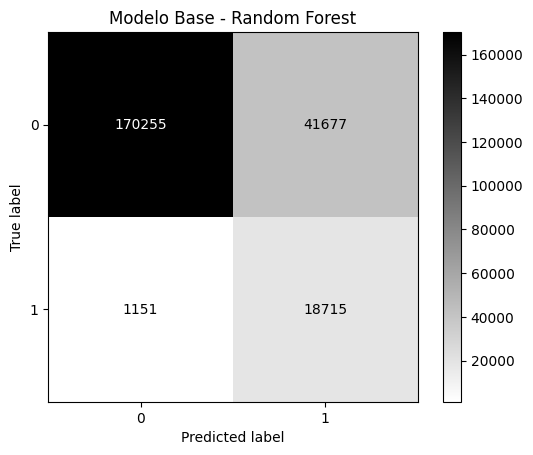

In [16]:
cm = confusion_matrix(teste2['y'], teste2['y_palavra'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title("Modelo Base - Random Forest")
plt.show()

In [17]:
fp = teste2[(teste2['y'] == 0) & (teste2['y_palavra'] == 1)]
fp.to_csv(PATH_FALSOS_NEGATIVOS_MODELO_1, index=False,columns=['palavra'])
fp.shape

(41677, 4)

In [18]:
accuracy = accuracy_score(teste2['y'], teste2['y_palavra'])
accuracy

0.8152356793414957

In [19]:
precision = precision_score(teste2['y'], teste2['y_palavra'])
precision

np.float64(0.30989203868061993)

In [20]:
recall = recall_score(teste2['y'], teste2['y_palavra'])
recall

np.float64(0.9420618141548374)

In [21]:
f1 = f1_score(teste2['y'], teste2['y_palavra'])
f1

np.float64(0.46637095367440007)